In [1]:
using Pkg
# adjust toktox_path to match the location of your cloned TokToxStability repo
toktox_path = "/Users/adrianaghiozzi/.julia/dev/TokToxStability"
Pkg.activate(toktox_path)
Pkg.instantiate()

  Activating project at `~/.julia/dev/TokToxStability`


In [2]:
venv_python = joinpath(toktox_path, ".venv", "bin", "python")
if !isfile(venv_python)
    run(`$(joinpath(toktox_path, "setup_venv.sh"))`)
end

In [3]:
ENV["JULIA_CONDAPKG_BACKEND"] = "Null"
ENV["JULIA_PYTHONCALL_EXE"] = venv_python

"/Users/adrianaghiozzi/.julia/dev/TokToxStability/.venv/bin/python"

In [4]:
using Revise
using TokToxStability
using Plots
using DataFrames
using PythonCall

In [5]:
# only call this once per kernel session
myOFT = TokToxStability.make_oft_env()   


#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        v26.6
Development branch:  main
Revision id:         f5ab95b

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



Python: <OpenFUSIONToolkit._core.OFT_env object at 0x311d0a120>

In [6]:
# An example kinetic EFIT and corresponding geqdsk for DIII-D shot 147131 are provided in cases/D3D
gpec_settings = TokToxStability.GPECSettings(toroidal_mode_number = 1)
kinetic_efit_path = joinpath(pkgdir(TokToxStability), "cases/D3D/g147131.02300_DIIID_KEFIT.kin")
geqdsk_path = joinpath(pkgdir(TokToxStability), "cases/D3D/g147131.02300_DIIID_KEFIT.eqdsk")


"/Users/adrianaghiozzi/.julia/dev/TokToxStability/cases/D3D/g147131.02300_DIIID_KEFIT.eqdsk"

In [7]:
profiles = TokToxStability.read_kinetic_profiles_from_file(kinetic_efit_path)
equilibrium = TokToxStability.read_equilibrium_from_file(geqdsk_path)


TokToxStability.Equilibrium([0.0, 0.0078125, 0.015625, 0.0234375, 0.03125, 0.0390625, 0.046875, 0.0546875, 0.0625, 0.0703125  …  0.9296875, 0.9375, 0.9453125, 0.953125, 0.9609375, 0.96875, 0.9765625, 0.984375, 0.9921875, 1.0], nothing, nothing, 1.69550002, -1.7227961, 1.18663454e6, 76762.0766, [1.08649712 0.0; 1.09147054 0.1; … ; 1.08606136 -0.025; 1.08649712 0.0], [-0.911430759, -0.946775258, -0.976776409, -1.00206207, -1.02318633, -1.04063817, -1.0548491, -1.06619994, -1.07502677, -1.08162616  …  0.171213058, 0.290801074, 0.483881839, 0.671604565, 0.746098232, 0.715833223, 0.616102304, 0.480663723, 0.334205417, 0.20021433], [-620844.41, -605164.368, -590721.145, -577369.417, -564980.938, -553442.532, -542654.324, -532528.173, -522986.299, -513960.063  …  -341873.422, -420296.619, -549904.238, -665250.784, -679899.319, -605373.806, -475780.814, -324936.214, -197176.492, -108641.837])

In [8]:
mygs = TokToxStability.setup_tokamaker_from_file!(:D3D, profiles, equilibrium, myOFT)



**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =    8912
    # of edges   =   26573
    # of cells   =   17662
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  8.702E-04
    hrms =  4.833E-02
    hmax =  1.540E-01
  Surface grounded at vertex    1733


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing flux BC matrix 
 Inverting real matrix
   Time =    1.5499999999999999E-003
Starting non-linear GS solver
     1 -1.6730E+00 -1.2573E-06  1.4550E-01  1.7610E+00  2.2573E-02 -4.9357E+03
     2 -1.8259E+00 -1.2740E-06  3.1527E-02  1.7614E+00  2.3709E-02  1.4707E+04
     3 -1.9088E+00 -1.2732E-06  6.9955E-03  1.7608E+00  2.4323E-02  1.4288E+04
     4 -1.9485E+00 -1.2681E-06  1.6348E-03  1.7602E+00  2.4649E-02  1.3448E+04
     5 -1.9645E+00 -1.2651E-06

Python: <OpenFUSIONToolkit.TokaMaker._core.TokaMaker object at 0x15e7d0980>

Equilibrium Statistics:
  Topology                =   Diverted
  Toroidal Current [A]    =    1.1866E+06
  Current Centroid [m]    =    1.693 -0.001
  Magnetic Axis [m]       =    1.759  0.025
  Elongation              =    1.780 (U:  1.565, L:  1.995)
  Triangularity           =    0.454 (U:  0.226, L:  0.681)
  Plasma Volume [m^3]     =   19.070
  q_0, q_95               =    1.077  4.230
  Plasma Pressure [Pa]    =   Axis:  7.6599E+04, Peak:  7.6599E+04
  Stored Energy [J]       =    7.3713E+05
  <Beta_pol> [%]          =   82.7478
  <Beta_tor> [%]          =    2.1656
  <Beta_n>   [%]          =    1.9054
  Diamagnetic flux [Wb]   =    1.0667E-02
  Toroidal flux [Wb]      =    3.4614E+00
  l_i                     =    0.8772


In [9]:
# The gEQDSK files created by TokaMaker at each coarse scan iteration can be saved by setting working_directory
# For a file-less option, set working_directory = nothing, which will save the gEQDSKs to a temporary directory that is deleted after the run
working_directory = nothing

# starting_fraction sets the first scaling of the temperature profile to be applied in the beta limit search
# step sets the spread of the subsequent scalings 
starting_fraction = 1.0 
step = 0.25 

coarse_scan_results = TokToxStability.coarse_scan_until_unstable(mygs, starting_fraction, step, equilibrium, profiles, gpec_settings; working_directory = working_directory);


Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_Pvm4gA/f1p0000/tokamaker_f1p0000.geqdsk


Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_nNlfKK/f1p2500/tokamaker_f1p2500.geqdsk


Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_ltFliR/f1p5000/tokamaker_f1p5000.geqdsk


Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_7MjPaZ/f1p7500/tokamaker_f1p7500.geqdsk


In [10]:
# Creates a DataFrame with the results of the scan 
cols = (:fraction, :beta_n, :dW_total, :dW_plasma, :dW_vacuum, :qmax, :msing)
DataFrame([NamedTuple{cols}(r[c] for c in cols) for r in coarse_scan_results])

Row,fraction,beta_n,dW_total,dW_plasma,dW_vacuum,qmax,msing
,Float64,Float64,Float64,Float64,Float64,Float64,Int64
1,1.0,1.5994,0.588592,-2.1802,2.76879,5.47073,4
2,1.25,1.99532,0.317057,-2.96972,3.28678,5.57294,4
3,1.5,2.38951,-0.0596664,-3.98547,3.9258,5.67666,4
4,1.75,2.78248,-0.566463,-5.23048,4.66402,5.79056,4


In [11]:
# estimate_beta_limit function interpolates the zero crossing of dW_total based on the scanned points
# If the limit wasn't reached, try re-running coarse_scan_until_unstable with a larger starting_fraction
bl = TokToxStability.estimate_beta_limit(coarse_scan_results)


estimate_beta_limit: dW_total crossing bracketed between the scanned points beta_N=1.9953 and beta_N=2.3895 -- interpolated crossing at beta_N=2.3271.


(beta_n_crossing = 2.327077432299187, beta_n_lo = 1.9953222459614333, beta_n_hi = 2.389509901983439, bracketed = true)

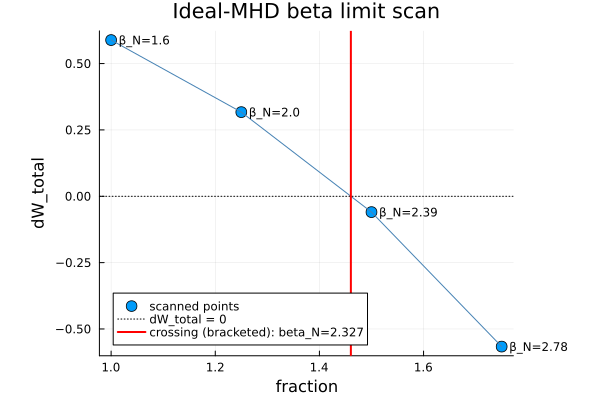

In [12]:
TokToxStability.plot_beta_scan_summary(coarse_scan_results; beta_limit=bl)


In [13]:
# Each scan point also carries GPEC's classical linear tearing Delta' matrix (ideal-MHD outer-region
# matching, PEST3 convention), since kinetic_factor=0 in gpec_settings above. It's indexed by rational
# surface, not by mode numbers, so singular_surfaces (the (m, n, q) of each row/column) is carried
# alongside it -- see delta_prime_for_mode below.
coarse_scan_results[1].singular_surfaces

4-element Vector{@NamedTuple{m::Vector{Int64}, n::Vector{Int64}, q::Float64}}:
 (m = [2], n = [1], q = 2.0)
 (m = [3], n = [1], q = 3.0)
 (m = [4], n = [1], q = 4.0)
 (m = [5], n = [1], q = 5.0)

In [14]:
# Delta' [1/m] for the 2/1 mode (m=2, n=1) at each scanned point. `missing` would mean the q=2
# surface wasn't present in the equilibrium at that point.
[TokToxStability.delta_prime_for_mode(r, 2, 1) for r in coarse_scan_results]

4-element Vector{Float64}:
   9.562087395631204
  16.84097143294307
 -71.44849016170924
  -7.331096465139246

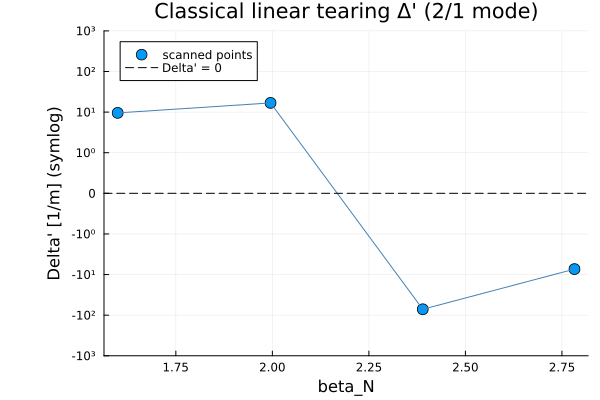

In [15]:
# In the classical (constant-psi, ideal-outer-region) picture, Delta' > 0 is unstable to tearing
# (the island grows) and Delta' < 0 is stable -- this is Delta', not the Delta_eff of a kinetic/
# resistive-layer-corrected dispersion relation, so treat the sign change as indicative, not final.
# Note the outer-region matching also gets numerically noisy close to the ideal-MHD marginal point
# (dW_total ~ 0, beta_N ~ 2.3 above) -- expect Delta' itself to be less trustworthy there.
TokToxStability.plot_delta_prime_scan(coarse_scan_results, 2, 1)

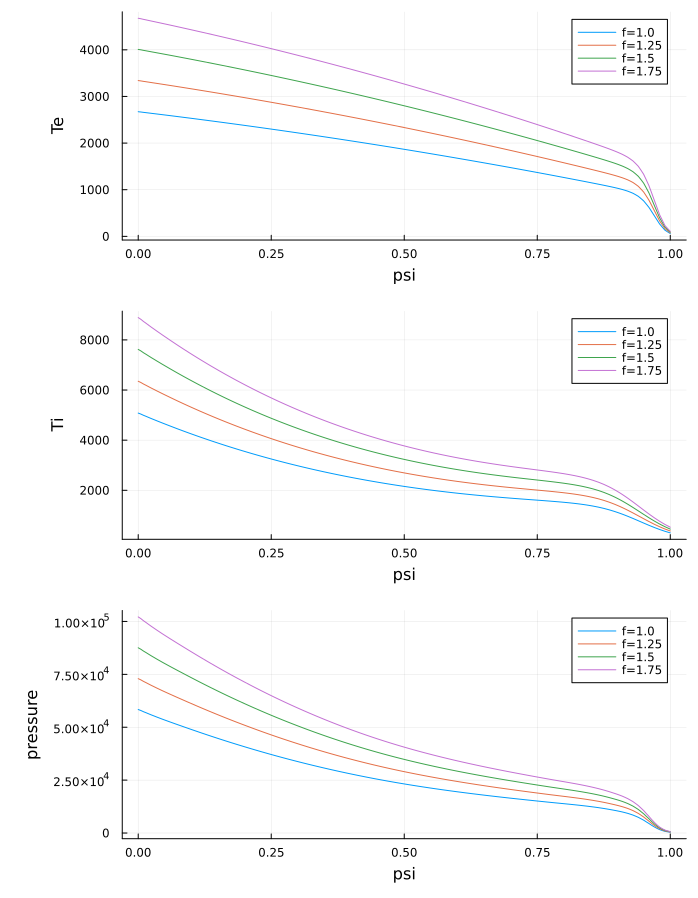

In [16]:
TokToxStability.plot_profiles(coarse_scan_results)
